# 03 — Depuración, población objetivo, variables objetivo y EDA

**Objetivo:** pasar de 113.937 créditos a la población que nos interesa (créditos en dificultad), construir las variables objetivo **A** (¿se recupera algo?) y **B** (¿cuánto?), y entender qué se relaciona con la recuperación.

**Momento de predicción:** cuando el crédito entra a cobranza.

**Resultados que guarda:**
- `data/interim/poblacion_objetivo.parquet`
- `docs/resumen_objetivos.csv`, `docs/chequeos_consistencia.csv`
- Gráficas `docs/figuras/03_*.png`

## 1. Preparación

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RUTAS
from src.objetivo import (diagnosticar_duplicados, depurar_duplicados, seleccionar_poblacion,
                          chequeos_consistencia, construir_objetivos, resumen_objetivos,
                          marcar_madurez, curva_maduracion, sensibilidad_ventana,
                          VENTANA_MADURACION_MESES)

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.dpi'] = 110

def guardar_figura(fig, nombre):
    fig.savefig(RUTAS['figuras'] / nombre, dpi=150, bbox_inches='tight')

df = pd.read_parquet(RUTAS['data_interim'] / 'prosper_crudo.parquet')
print(f'Cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas')

Cargado: 113,937 filas x 81 columnas


## 2. ¿Por qué hay créditos repetidos?
Antes de borrar, entendemos qué columnas cambian entre las filas repetidas de un mismo `LoanKey`.

📋 **Pega esta salida.**

In [2]:
diag = diagnosticar_duplicados(df)
print('Grupos de LoanKey repetidos:', df.loc[df['LoanKey'].duplicated(keep=False), 'LoanKey'].nunique())
print('Filas por grupo (máximo):', df['LoanKey'].value_counts().max())
print('\nColumnas que cambian dentro de los grupos repetidos (n.º de grupos):')
diag

Grupos de LoanKey repetidos: 827
Filas por grupo (máximo): 6

Columnas que cambian dentro de los grupos repetidos (n.º de grupos):


ProsperScore    827
dtype: int64

## 3. Depurar: una fila por crédito
**Hallazgo de la sección 2:** las filas repetidas solo difieren en `ProsperScore` (827 grupos). Regla **conservadora**: conservar el `ProsperScore` más bajo (mayor riesgo), porque no hay forma de saber cuál es el correcto.

In [3]:
df = depurar_duplicados(df)
assert df['LoanKey'].is_unique, 'Todavía hay LoanKey repetidos'
print('✅ LoanKey único')

Filas antes: 113,937 | después: 113,066 | eliminadas: 871
✅ LoanKey único


## 4. Población objetivo: Chargedoff + Defaulted

In [4]:
pob = seleccionar_poblacion(df)
pob['LoanStatus'].value_counts().to_frame('creditos')

Población objetivo: 17,010 créditos (15.0% del total depurado)


,creditos
LoanStatus,
Chargedoff,11992
Defaulted,5018


## 5. Chequeos de consistencia de las columnas LP_*
Antes de construir el objetivo verificamos que las columnas se comporten como esperamos. Cada cifra es el **% de créditos** que cumple la condición.

📋 **Pega esta tabla**: de ella depende la definición final del objetivo.

In [5]:
chequeos = chequeos_consistencia(pob)
chequeos

,creditos,exposicion_cero_o_negativa,neta_mayor_que_bruta,recupera_capital,recupera_no_capital,no_capital_negativo,closeddate_nula
LoanStatus,,,,,,,
Chargedoff,11992,0.02,10.95,18.39,17.08,0.0,0.0
Defaulted,5018,2.11,13.15,32.16,24.17,0.0,0.0
TOTAL,17010,0.63,11.60,22.45,19.17,0.0,0.0


## 6. Construir las variables objetivo
- **Exposición** = `LP_GrossPrincipalLoss` (capital pendiente al castigo)
- **Recuperación total** = (`LP_GrossPrincipalLoss` − `LP_NetPrincipalLoss`) + `LP_NonPrincipalRecoverypayments`
- **A** = 1 si la recuperación total ≥ 1 USD
- **B** = tasa de recuperación (recuperación / exposición) y monto en USD

📋 **Pega esta tabla.**

**Ajustes tras los chequeos:** recuperación de capital negativa → 0; tasa B acotada a [0, 1]; créditos sin exposición → excluidos del modelado.

In [6]:
pob = construir_objetivos(pob)
resumen = resumen_objetivos(pob)
resumen.T

LoanStatus,Chargedoff,Defaulted,TOTAL
creditos,11992.00,5018.00,17010.00
pct_exposicion_valida,99.98,97.89,99.37
pct_recupera_algo (A=1),19.36,27.12,21.65
exposicion_total_usd,55912922.00,23893833.00,79806755.00
recuperado_total_usd,2352706.00,2751275.00,5103981.00
tasa_recuperacion_cartera_pct,4.21,11.51,6.40
tasa_mediana_si_recupera_pct,10.78,70.11,18.68
pct_tasa_mayor_100,1.21,9.65,3.70


## 7. Distribución de los objetivos

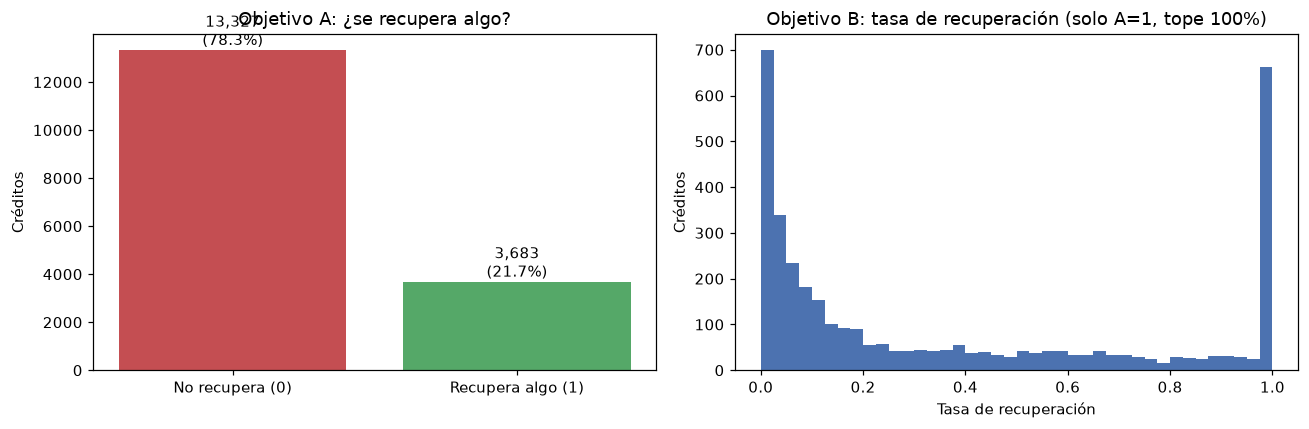

Percentiles de la tasa B (solo A=1):
count    3682.000
mean        0.376
std         0.382
min         0.000
10%         0.008
25%         0.041
50%         0.187
75%         0.730
90%         1.000
max         1.000
Name: objetivo_B_tasa, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

conteo_A = pob['objetivo_A'].value_counts().sort_index()
axes[0].bar(['No recupera (0)', 'Recupera algo (1)'], conteo_A.values, color=['#C44E52', '#55A868'])
for i, v in enumerate(conteo_A.values):
    axes[0].text(i, v, f'{v:,}\n({v / conteo_A.sum():.1%})', ha='center', va='bottom')
axes[0].set_title('Objetivo A: ¿se recupera algo?')
axes[0].set_ylabel('Créditos')

tasa = pob.loc[pob['objetivo_A'] == 1, 'objetivo_B_tasa'].clip(upper=1)
axes[1].hist(tasa.dropna(), bins=40, color='#4C72B0')
axes[1].set_title('Objetivo B: tasa de recuperación (solo A=1, tope 100%)')
axes[1].set_xlabel('Tasa de recuperación')
axes[1].set_ylabel('Créditos')

plt.tight_layout(); guardar_figura(fig, '03_objetivos.png'); plt.show()

print('Percentiles de la tasa B (solo A=1):')
print(tasa.describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

## 8. ¿Hay censura en los créditos recientes?
Los créditos castigados poco antes de la extracción (2014) **no han tenido tiempo** de mostrar recuperaciones. Si es así, su tasa de recuperación sale artificialmente baja, y eso afecta directamente la validación temporal.

📋 **Pega esta tabla.**

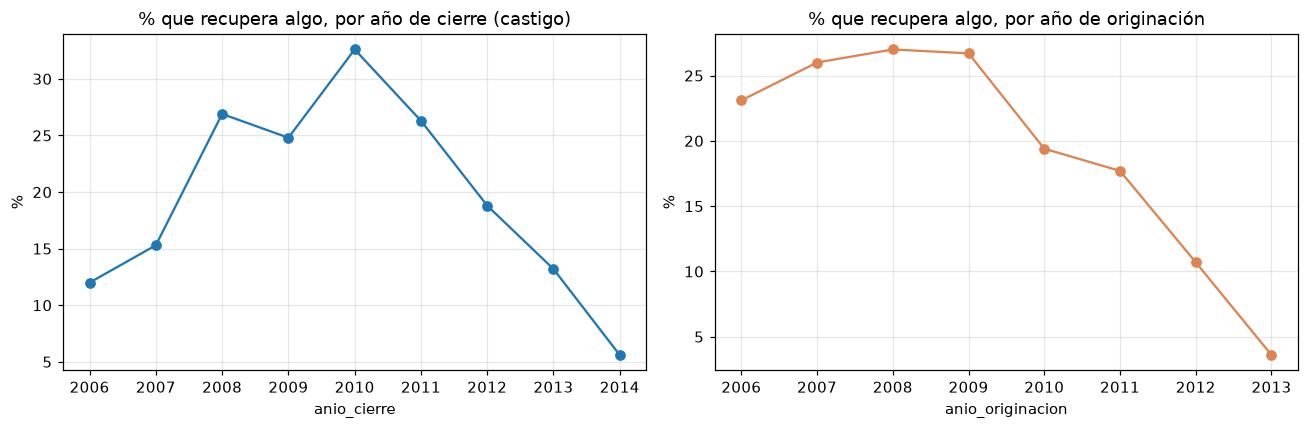

Por año de cierre:


,creditos,pct_recupera,exposicion,recuperado,tasa_cartera_pct
anio_cierre,,,,,
2006,100,12.0,422568.08,1.861847e+04,4.4
2007,1682,15.3,7336783.26,1.519670e+05,2.1
2008,2948,26.9,16804876.21,1.170660e+06,7.0
2009,3814,24.8,18335714.75,1.587482e+06,8.7
2010,1845,32.6,5160306.72,7.988846e+05,15.5
2011,1069,26.3,2817384.80,2.977960e+05,10.6
2012,1931,18.8,9110433.99,6.094621e+05,6.7
2013,2976,13.2,15905873.97,4.598822e+05,2.9
2014,645,5.6,3912813.14,9.228010e+03,0.2


Por año de originación:


,creditos,pct_recupera
anio_originacion,,
2006,2325,23.1
2007,4524,26.0
2008,3808,27.0
2009,311,26.7
2010,937,19.4
2011,2145,17.7
2012,2622,10.7
2013,338,3.6


In [8]:
pob['anio_cierre'] = pob['ClosedDate'].dt.year
pob['anio_originacion'] = pob['LoanOriginationDate'].dt.year

por_cierre = pob.groupby('anio_cierre').agg(creditos=('objetivo_A', 'size'),
                                            pct_recupera=('objetivo_A', 'mean'),
                                            exposicion=('exposicion_castigo', 'sum'),
                                            recuperado=('recuperacion_total', 'sum'))
por_cierre['pct_recupera'] = (por_cierre['pct_recupera'] * 100).round(1)
por_cierre['tasa_cartera_pct'] = (por_cierre['recuperado'] / por_cierre['exposicion'] * 100).round(1)

por_orig = pob.groupby('anio_originacion').agg(creditos=('objetivo_A', 'size'),
                                              pct_recupera=('objetivo_A', 'mean'))
por_orig['pct_recupera'] = (por_orig['pct_recupera'] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
por_cierre['pct_recupera'].plot(marker='o', ax=axes[0], title='% que recupera algo, por año de cierre (castigo)')
por_orig['pct_recupera'].plot(marker='o', ax=axes[1], color='#DD8452', title='% que recupera algo, por año de originación')
for ax in axes: ax.set_ylabel('%'); ax.grid(alpha=.3)
plt.tight_layout(); guardar_figura(fig, '03_recuperacion_por_anio.png'); plt.show()

print('Por año de cierre:'); display(por_cierre)
print('Por año de originación:'); display(por_orig)

## 8b. Ventana de maduración (corrección de la censura)
La sección 8 mostró que los créditos cerrados en 2013–2014 recuperan mucho menos: **no han tenido tiempo**. Medimos cómo crece el % que recupera según los meses de observación después del cierre. Donde la curva se estabiliza está la ventana mínima.

- **Fecha de corte** = fecha más reciente del dataset (proxy de la fecha de extracción).
- Créditos **maduros** (≥ ventana) → entrenamiento y validación.
- Créditos **inmaduros** → no se usan para entrenar; quedan como cartera para demostrar la priorización en la app.

📋 **Pega las dos tablas.**

Fecha de corte (proxy de extracción): 2014-03-12


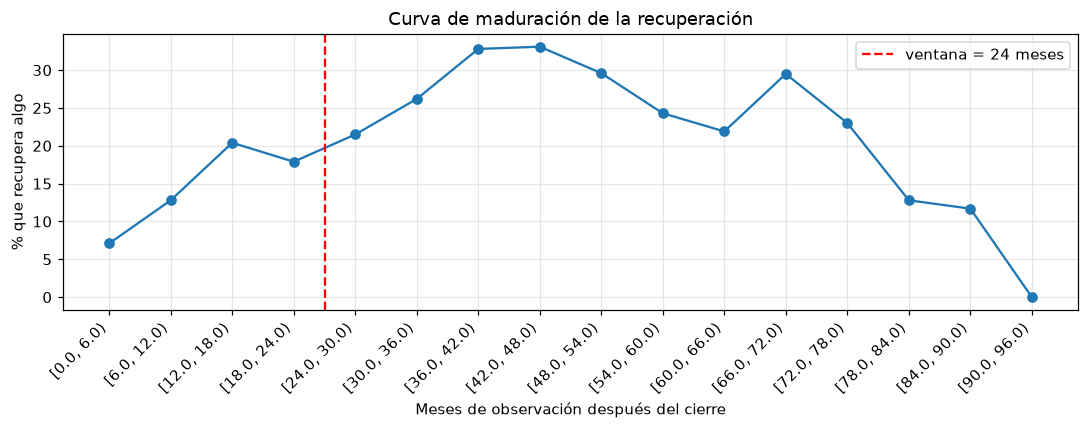

Curva de maduración:


,creditos,pct_recupera,tasa_cartera_pct
meses_observacion,,,
"[0.0, 6.0)",1588,7.1,0.6
"[6.0, 12.0)",1419,12.8,3.1
"[12.0, 18.0)",1412,20.4,6.5
"[18.0, 24.0)",861,17.9,5.9
"[24.0, 30.0)",648,21.5,7.5
"[30.0, 36.0)",470,26.2,13.0
"[36.0, 42.0)",716,32.8,16.0
"[42.0, 48.0)",869,33.1,15.7
"[48.0, 54.0)",1509,29.6,12.6



Sensibilidad a la ventana elegida:


,creditos_modelado,pct_poblacion,pct_recupera_A,creditos_inmaduros
ventana_meses,,,,
12,13932,81.9,24.3,2970
18,12543,73.7,24.7,4359
24,11706,68.8,25.2,5196
30,11078,65.1,25.4,5824
36,10610,62.4,25.3,6292


In [9]:
fecha_corte = df[['ListingCreationDate', 'LoanOriginationDate', 'ClosedDate']].max().max()
print('Fecha de corte (proxy de extracción):', fecha_corte.date())

pob = marcar_madurez(pob, fecha_corte)
curva = curva_maduracion(pob)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(curva)), curva['pct_recupera'], marker='o')
ax.set_xticks(range(len(curva)), curva.index, rotation=45, ha='right')
ax.axvline(VENTANA_MADURACION_MESES / 6 - 0.5, color='red', ls='--', label=f'ventana = {VENTANA_MADURACION_MESES} meses')
ax.set_xlabel('Meses de observación después del cierre'); ax.set_ylabel('% que recupera algo')
ax.set_title('Curva de maduración de la recuperación'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); guardar_figura(fig, '03_curva_maduracion.png'); plt.show()

print('Curva de maduración:'); display(curva)
print('\nSensibilidad a la ventana elegida:'); display(sensibilidad_ventana(pob))

## 9. Variable a revisar: `LoanFirstDefaultedCycleNumber`
¿Está disponible para nuestra población? Si sí, puede ser una predictora muy valiosa (cuántas cuotas pagó antes de caer).

In [10]:
col = 'LoanFirstDefaultedCycleNumber'
print(pob.groupby('LoanStatus')[col].apply(lambda s: f'{s.notna().mean():.1%} con dato'))
print(pob[col].describe().round(1))

LoanStatus
Chargedoff    99.9% con dato
Defaulted     97.9% con dato
Name: LoanFirstDefaultedCycleNumber, dtype: str
count    16898.0
mean        16.3
std          9.0
min          0.0
25%          9.0
50%         14.0
75%         22.0
max         44.0
Name: LoanFirstDefaultedCycleNumber, dtype: float64


## 10. EDA: ¿qué se relaciona con la recuperación?
Usamos **solo créditos maduros** (para que la censura no distorsione) y comparamos el **% que recupera algo (A)** y la **tasa de recuperación de la cartera** por grupos. Es exploración, no causalidad: el modelo confirmará qué variables pesan.

Para la calificación de riesgo unimos las dos épocas: `CreditGrade` (antigua) y `ProsperRating (Alpha)` (reciente).

EDA sobre 11,706 créditos maduros con exposición válida
Term         12    36  60
anio_cierre              
2006          0   100   0
2007          0  1682   0
2008          0  2948   0
2009          0  3813   0
2010          0  1844   0
2011          4  1043   7
2012          8   255   2


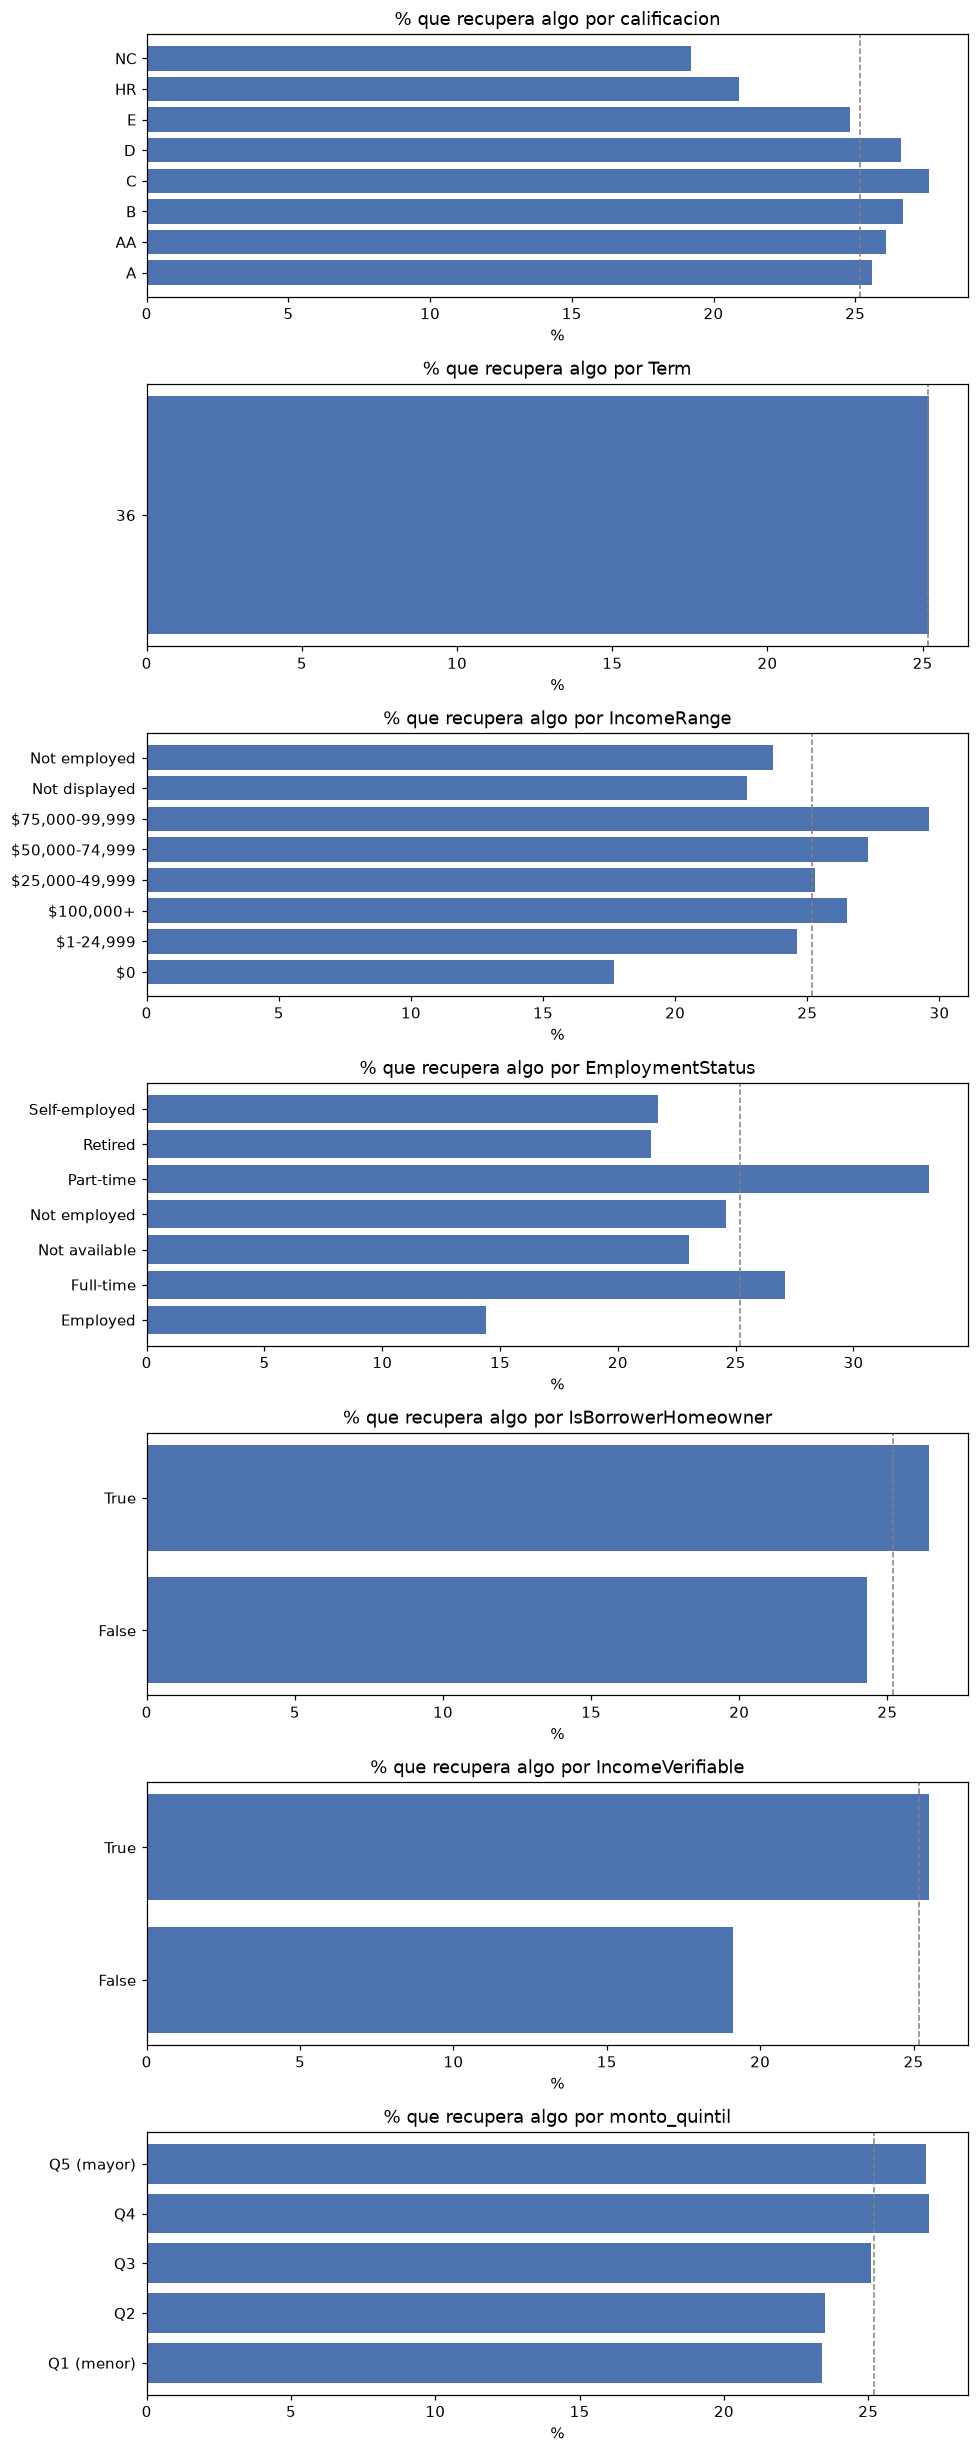

In [11]:
pob['calificacion'] = pob['ProsperRating (Alpha)'].fillna(pob['CreditGrade'])
eda = pob[pob['en_modelado']].copy()
print(f'EDA sobre {len(eda):,} créditos maduros con exposición válida')
eda['monto_quintil'] = pd.qcut(eda['LoanOriginalAmount'], 5,
                             labels=['Q1 (menor)', 'Q2', 'Q3', 'Q4', 'Q5 (mayor)'])

def tabla_recuperacion(var):
    t = eda.groupby(var, observed=True).agg(creditos=('objetivo_A', 'size'),
                                           pct_recupera=('objetivo_A', 'mean'),
                                           exposicion=('exposicion_castigo', 'sum'),
                                           recuperado=('recuperacion_total', 'sum'))
    t['pct_recupera'] = (t['pct_recupera'] * 100).round(1)
    t['tasa_cartera_pct'] = (t['recuperado'] / t['exposicion'].where(t['exposicion'] > 0) * 100).round(1)
    return t[t['creditos'] >= 30].drop(columns=['exposicion', 'recuperado'])

variables = ['calificacion', 'Term', 'IncomeRange', 'EmploymentStatus',
             'IsBorrowerHomeowner', 'IncomeVerifiable', 'monto_quintil']
# Plazo agrupado con el año de cierre: los créditos a 60 meses existen solo desde 2010
print(pd.crosstab(eda['anio_cierre'], eda['Term']))
tablas = {v: tabla_recuperacion(v) for v in variables}

fig, axes = plt.subplots(len(variables), 1, figsize=(9, 3.2 * len(variables)))
for ax, v in zip(axes, variables):
    t = tablas[v]
    ax.barh(t.index.astype(str), t['pct_recupera'], color='#4C72B0')
    ax.axvline(eda['objetivo_A'].mean() * 100, color='gray', ls='--', lw=1, label='promedio')
    ax.set_title(f'% que recupera algo por {v}'); ax.set_xlabel('%')
plt.tight_layout(); guardar_figura(fig, '03_eda_recuperacion.png'); plt.show()

📋 **Pega estas tablas** (son las que alimentan el análisis del documento y el resultado de la Fase 3).

In [12]:
for v, t in tablas.items():
    print(f'\n===== {v} =====')
    print(t.to_string())


===== calificacion =====
              creditos  pct_recupera  tasa_cartera_pct
calificacion                                          
A                  888          25.6               6.8
AA                 571          26.1               6.1
B                 1457          26.7               8.1
C                 2140          27.6               8.7
D                 2350          26.6               8.1
E                 1846          24.8               9.6
HR                2350          20.9               7.4
NC                  99          19.2               1.5

===== Term =====
      creditos  pct_recupera  tasa_cartera_pct
Term                                          
36       11685          25.2               7.9

===== IncomeRange =====
                creditos  pct_recupera  tasa_cartera_pct
IncomeRange                                             
$0                   226          17.7               4.7
$1-24,999           1069          24.6               8.7
$100,000+   

## 11. Guardar resultados

In [13]:
print(pob.groupby(['madura', 'exposicion_valida']).size().rename('creditos').to_frame())
print(f"\n➡️ Créditos para modelar (en_modelado): {pob['en_modelado'].sum():,}")

salida = RUTAS['data_interim'] / 'poblacion_objetivo.parquet'
pob.to_parquet(salida, index=False)
resumen.to_csv(RUTAS['docs'] / 'resumen_objetivos.csv', encoding='utf-8-sig')
chequeos.to_csv(RUTAS['docs'] / 'chequeos_consistencia.csv', encoding='utf-8-sig')

print('✅ Guardado:', salida.relative_to(RUTAS['raiz']), f'({len(pob):,} filas)')
print('   docs/resumen_objetivos.csv, docs/chequeos_consistencia.csv, docs/figuras/03_*.png')

                          creditos
madura exposicion_valida          
False  False                    84
       True                   5196
True   False                    24
       True                  11706

➡️ Créditos para modelar (en_modelado): 11,706
✅ Guardado: data\interim\poblacion_objetivo.parquet (17,010 filas)
   docs/resumen_objetivos.csv, docs/chequeos_consistencia.csv, docs/figuras/03_*.png
